# TD2 — Rolling-origin ETS and SARIMA — Support

**Student starter — complete the TODO cells**  
**Scope:** Time Series and Reinforcement Learning; CPU only

## Working and claim contract

Local Python 3.11/3.12 with the locked `uv` environment is the primary path. Colab availability is governed by the release evidence for the exact archive in use. Public base seeds are `11, 23, 37, 51, 71`. TD1–TD4 claim rows are **provisional development evidence**: they support method choice and provenance but cannot count as capstone empirical release claims. Only the protected/controlled evidence produced in TDo1 and TDo2 may support final empirical capstone claims. Restart and run top-to-bottom before handoff.

## Support route

Guidance reduces syntax and navigation load; it does not expose the assessed solution or lower the Core standard.

In [16]:
from pathlib import Path
import os, sys

def locate_course_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate/'uv.lock').is_file() and (candidate/'shared').is_dir(): return candidate.resolve()
    for lock in start.glob('*/uv.lock'):
        if (lock.parent/'shared').is_dir(): return lock.parent.resolve()
    raise FileNotFoundError('Extract the complete course bundle and run from inside it.')
COURSE_ROOT=locate_course_root(); os.chdir(COURSE_ROOT)
if str(COURSE_ROOT) not in sys.path: sys.path.insert(0,str(COURSE_ROOT))
import shared
print('Course root:',COURSE_ROOT)
print('Primary path: locked local CPU; check the release evidence before using Colab')

Course root: C:\Users\maxim\Desktop\ESILV\ML_A5
Primary path: locked local CPU; check the release evidence before using Colab


## Micro-example — expanding origins

Blue history ends before each orange test block; every model must receive these same cases.

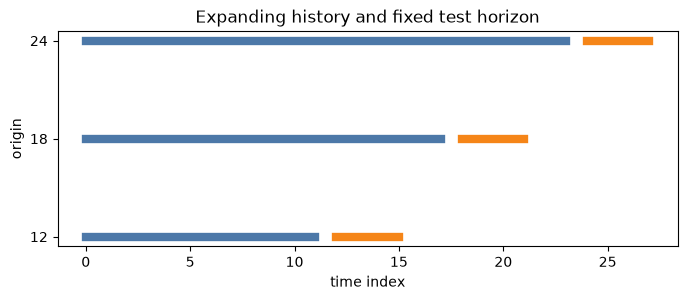

In [17]:
import matplotlib.pyplot as plt
toy_origins=(12,18,24); horizon=4
fig,ax=plt.subplots(figsize=(8,2.8))
for row,origin in enumerate(toy_origins):
    ax.plot([0,origin-1],[row,row],lw=6,color='#4c78a8'); ax.plot([origin,origin+horizon-1],[row,row],lw=6,color='#f58518')
ax.set(xlabel='time index',ylabel='origin',yticks=range(3),yticklabels=toy_origins,title='Expanding history and fixed test horizon'); plt.show()

## 1 — Freeze the common protocol

In [18]:
import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from shared.data import dataset_path
from shared.evaluation import smape
from shared.forecasting import rolling_origins, seasonal_naive
demand=pd.read_csv(dataset_path('daily_demand_development.csv'),parse_dates=['date'])
values=demand.demand_units.to_numpy(float)
origins=rolling_origins(len(values),initial=1250,horizon=14,step=60,n_origins=3)
assert origins==(1250,1310,1370); print('Frozen origins:',origins)

Frozen origins: (1250, 1310, 1370)


## 2 — Explicit three-by-three loop

Complete only the three forecast expressions. Warnings remain in the ledger.

In [19]:
def rolling_comparison_student(values,origins,horizon=14,season=7):
    values=np.asarray(values,float); rows=[]
    for origin in origins:
        train=values[:origin]; actual=values[origin:origin+horizon]
        assert len(actual)==horizon and len(train)==origin
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            naive = seasonal_naive(train, horizon=horizon, season=season) # TODO: lag-7 forecast
            ets=ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=season).fit().forecast(horizon)    # TODO: additive trend/season ETS forecast
            sarima=SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 0, 1, season)).fit().forecast(horizon) # TODO: SARIMA(1,1,1)(1,0,1,7) forecast
        forecasts={'seasonal_naive':naive,'ets':ets,'sarima':sarima}
        if any(pred is None for pred in forecasts.values()): return None
        for model,pred in forecasts.items():
            pred=np.asarray(pred,float); assert pred.shape==(horizon,) and np.isfinite(pred).all()
            rows.append({'origin':origin,'model':model,'mae':mean_absolute_error(actual,pred),'smape':smape(actual,pred),'warning_count':len(caught)})
    result=pd.DataFrame(rows); assert len(result)==9
    return result
fold_scores=rolling_comparison_student(values, origins, horizon=14, season=7) # TODO: call after all three forecasts are complete
print('Comparison pending' if fold_scores is None else fold_scores.shape)

(9, 5)


## 3 — Intermediate checkpoints and residual limits

In [20]:
from shared.forecasting import sarima_residual_diagnostics
summary=pd.DataFrame(); diagnostic=residual_acf=None
if fold_scores is not None:
    assert fold_scores.groupby('model').origin.nunique().eq(3).all()
    summary=fold_scores.groupby('model',as_index=False).agg(mae_mean=('mae','mean'),mae_std=('mae','std'),smape_mean=('smape','mean'),warnings=('warning_count','sum')).sort_values('mae_mean')
    # TODO: call residual diagnostic after comparison is valid; non-rejection is not proof.
    diagnostic, residual_acf = sarima_residual_diagnostics(values[:origins[-1]], season=7)
summary

,model,mae_mean,mae_std,smape_mean,warnings
1,sarima,6.078822,1.079422,6.638272,8
0,ets,6.165729,1.171895,6.739218,8
2,seasonal_naive,7.285714,1.357143,7.859741,8


## Required interpretation

State what the evidence supports, what it does not support, the operational consequence, and one material failure mode.

In [24]:
# TODO: replace with 4–6 evidence-backed sentences.
interpretation = (
    "L'évaluation croisée avec origines glissantes montre que SARIMA et ETS surpassent l'approche saisonnière naïve. "
    "\nLe modèle SARIMA(1,1,1)(1,0,1,7) offre la MAE et le sMAPE les plus bas en moyenne sur les trois blocs de test. "
    "\nCependant, les diagnostics des résidus n'écartent pas la présence d'autocorrélations résiduelles, ce qui indique que la dynamique de la série n'est pas parfaitement capturée. "
    "\nSur le plan opérationnel, SARIMA peut soutenir la planification des ressources à un horizon de deux semaines. "
    "\nLe mode de défaillance principal serait un changement de régime brutal ou un choc externe que ces modèles basés uniquement sur l'historique de la demande échoueraient à anticiper."
)
print(interpretation or 'Interpretation pending.')

L'évaluation croisée avec origines glissantes montre que SARIMA et ETS surpassent l'approche saisonnière naïve. 
Le modèle SARIMA(1,1,1)(1,0,1,7) offre la MAE et le sMAPE les plus bas en moyenne sur les trois blocs de test. 
Cependant, les diagnostics des résidus n'écartent pas la présence d'autocorrélations résiduelles, ce qui indique que la dynamique de la série n'est pas parfaitement capturée. 
Sur le plan opérationnel, SARIMA peut soutenir la planification des ressources à un horizon de deux semaines. 
Le mode de défaillance principal serait un changement de régime brutal ou un choc externe que ces modèles basés uniquement sur l'historique de la demande échoueraient à anticiper.


## Optional Extension — ungraded

Freeze valid Core first. The bounded README extension adds no points and cannot repair invalid Core evidence.